# Tarea 2 · Parte 2 — De los modelos base a la extracción estructurada

Medimos qué tan bien leen y escuchan los modelos, con **los mismos 10 documentos y 10 clips** de la Parte 1
y transcripciones de referencia hechas a mano. Luego un LLM local convierte cada texto en un JSON con campos
estructurados, y una auditoría humana de 20 casos mide cuánto se puede confiar en él.

1. Muestra de evaluación y referencias manuales
2. Normalización y métricas (CER y WER)
3. Línea base sin ajuste: PaddleOCR y faster-whisper *small*
4. Modelos alternativos: PaddleOCR con preprocesamiento, EasyOCR, Whisper *turbo* y Qwen3-ASR
5. Casos difíciles: manuscritos y audio con música
6. Extracción estructurada con Qwen3-1.7B y auditoría humana
7. Comparativa y decisión

**Regla de juego:** las configuraciones de todos los modelos (módulo `evaluacion.py`) se fijaron y se
corrieron **antes** de tener las referencias manuales; ningún parámetro se ajustó después de ver las métricas.

In [1]:
import json
import os
import re
import sys
import warnings
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
warnings.filterwarnings("ignore")

import jiwer
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

sys.path.insert(0, "scripts")
import evaluacion as ev
import extraccion_llm as ex
import seudonimos
import voz
from kit_auditoria import muestra as muestra_auditoria
from kit_transcripcion import MUESTRA_CLIPS, MUESTRA_DOCS

import logging
import transformers
logging.getLogger().setLevel(logging.ERROR)
for nombre in list(logging.root.manager.loggerDict):
    logging.getLogger(nombre).setLevel(logging.ERROR)
transformers.logging.set_verbosity_error()

pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width, pio.renderers["png"].height = 950, 480
pd.set_option("display.max_colwidth", 110)

DATOS = Path("datos")
documentos = pd.read_csv(DATOS / "documentos.csv", dtype={"texto_referencia": str})
transcripciones = pd.read_csv(DATOS / "transcripciones.csv", dtype={"texto_referencia": str})
from importlib.metadata import version
print(f"jiwer {version('jiwer')} · documentos {documentos.shape} · transcripciones {transcripciones.shape}")

jiwer 4.0.0 · documentos (25, 12) · transcripciones (32, 13)


## 1. Muestra de evaluación (sin datos nuevos)

Se eligieron de los corpus de la Parte 1, antes de correr cualquier métrica:

- **10 documentos** de los tres tipos (3 impresos, 3 fotos y 4 manuscritos), todos cortos para que la
  transcripción manual sea completa y cuidadosa;
- **10 clips** de tres orígenes distintos (Productora Huascarán, Nacional Films y productoras no
  identificadas) y condiciones de grabación variadas: narración limpia, narración con música de fondo y
  ambiente de playa o de calle.

In [2]:
muestra_docs = documentos.set_index("id").loc[MUESTRA_DOCS, ["tipo", "descripcion", "n_caracteres"]]
muestra_clips = transcripciones.set_index("id").loc[MUESTRA_CLIPS, ["titulo", "productora", "fecha_original", "duracion_seg", "segundos_voz"]]
print(muestra_docs["tipo"].value_counts().to_dict(), "·", muestra_clips["productora"].value_counts().to_dict())
display(muestra_docs)
display(muestra_clips)

{'manuscrito': 4, 'impreso': 3, 'foto': 3} · {'Productora Huascarán': 5, 'productora no identificada': 3, 'Nacional Films': 2}


,tipo,descripcion,n_caracteres
id,,,
doc_001,impreso,El Comercio (1939): aviso de manifestación cívica en la Plaza de Acho,204
doc_002,impreso,El Comercio (1939): «Mensaje del Presidente de la República»,421
doc_008,impreso,La Crónica (1945): «Instalóse en el Senado el Jurado Provincial de Elecciones de Lima»,815
doc_011,foto,«Tres discursos» (1945): portadilla del discurso del jefe del Partido Aprista,267
doc_012,foto,«Tres discursos» (1945): portadilla del discurso del Partido Vanguardia Socialista,266
doc_014,foto,El Comercio (1945): aviso del Partido Democrático Reformista,528
doc_021,manuscrito,"Carta de César Vallejo a José María Eguren (Trujillo, 1917)",767
doc_022,manuscrito,"Tarjeta de Ricardo Palma (1912), recorte de la parte manuscrita",237
doc_023,manuscrito,"Tarjeta de circulación de la Policía de Lima (1921), llenada a mano",362


,titulo,productora,fecha_original,duracion_seg,segundos_voz
id,,,,,
clip_001,Centenario del nacimiento de Don José Antonio Miro Quesada,Productora Huascarán,circa 1945,42.7,38.2
clip_006,El Dr. Eduardo Santos en el Country Club,productora no identificada,1940s,72.0,58.3
clip_007,El regreso del cardenal Guevara,Productora Huascarán,1940s,32.5,23.7
clip_012,Instalación del Instituto Indigenista Peruano,Nacional Films,1947,46.9,23.7
clip_015,Muere un sabio peruano (Fallecimiento de Julio C. Tello),Productora Huascarán,1947,59.0,49.2
clip_017,"Playas de ""Agua Dulce""",productora no identificada,1940s,53.9,44.4
clip_018,Preparativos de la expedición Kon Tiki,Nacional Films,circa 1947,59.0,49.1
clip_021,Reunión de boy-scouts en Lima,Productora Huascarán,1940s,46.5,32.5
clip_024,Se inaugura un teatro en Ancón,Productora Huascarán,1940s,49.3,18.9


### 1.1 Referencias manuales

El estudiante transcribió a mano los 20 casos en una página local (`scripts/kit_transcripcion.py`): cada
imagen o audio con un cuadro de texto, **sin ver las salidas de los modelos**. Documentos: línea por línea,
con la ortografía original. Audios: todo lo dicho, sin marcas de hablante.

Las referencias se publican en la columna `texto_referencia` con la misma seudonimización que los textos
de los modelos.

In [3]:
referencias = json.loads((DATOS / "raw" / "transcripcion_manual" / "referencias_manuales.json").read_text(encoding="utf-8"))
faltan = [i for i in MUESTRA_DOCS + MUESTRA_CLIPS if not referencias.get(i, "").strip()]
print(f"Referencias manuales: {sum(1 for i in MUESTRA_DOCS + MUESTRA_CLIPS if referencias.get(i, '').strip())} de 20 · faltan: {faltan}")

revision = pd.read_csv(DATOS / "privado" / "revision_nombres.csv")
reemplazos = seudonimos.tabla_de_reemplazos(revision)
publicar = {i: seudonimos.aplicar(referencias[i], reemplazos)[0] for i in MUESTRA_DOCS + MUESTRA_CLIPS}

documentos["texto_referencia"] = documentos["id"].map(publicar).fillna("")
transcripciones["texto_referencia"] = transcripciones["id"].map(publicar).fillna("")
documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)
pd.DataFrame({"id": list(publicar), "caracteres_referencia": [len(referencias[i]) for i in publicar],
              "palabras_referencia": [len(referencias[i].split()) for i in publicar]}).set_index("id").T

Referencias manuales: 20 de 20 · faltan: []


id,doc_001,doc_002,doc_008,doc_011,doc_012,doc_014,doc_021,doc_022,doc_023,doc_025,clip_001,clip_006,clip_007,clip_012,clip_015,clip_017,clip_018,clip_021,clip_024,clip_029
caracteres_referencia,236,421,813,268,270,533,802,322,365,557,607,609,411,351,748,741,756,348,359,637
palabras_referencia,44,70,133,45,41,94,141,49,58,90,101,93,61,56,127,133,122,52,57,100


## 2. Normalización y métricas

Referencia y salida automática pasan por **el mismo** criterio, `voz.normalizar` de la sesión 13
(minúsculas, sin puntuación, espacios simples; las tildes se conservan), después de quitar las marcas
que no son texto ni palabras habladas: `[HABLANTE_n]`, `[ilegible]`, `[inaudible]`, `[PERSONA_nn]`.

$$\text{CER} = \frac{S + D + I}{N_\text{caracteres de la referencia}} \qquad \text{WER} = \frac{S + D + I}{N_\text{palabras de la referencia}}$$

donde $S$, $D$ e $I$ son sustituciones, borrados e inserciones (distancia de Levenshtein). Reportamos dos
cifras: el **CER/WER agregado** (todos los errores sobre todos los caracteres o palabras de la muestra, como
`voz.cer` y `voz.wer`) y el **promedio por caso**, que da el mismo peso a un documento corto que a uno largo.

Las métricas se calculan sobre los textos **sin seudonimizar** (en local): así un nombre mal leído cuenta
como error, aunque en la publicación se cambie por un seudónimo.

In [4]:
MARCAS = re.compile(r"\[(?:HABLANTE_\d+|ilegible|inaudible|PERSONA_\d+)\]", flags=re.IGNORECASE)


def limpiar(texto: str) -> str:
    return voz.normalizar(MARCAS.sub(" ", str(texto or "")))


def cer(referencia, hipotesis):
    return jiwer.cer(limpiar(referencia), limpiar(hipotesis) or "∅")


def wer(referencia, hipotesis):
    return jiwer.wer(limpiar(referencia), limpiar(hipotesis) or "∅")


def agregado(metrica, referencias_, hipotesis_):
    return metrica([limpiar(r) for r in referencias_], [limpiar(h) or "∅" for h in hipotesis_])


print(limpiar("[HABLANTE_1] El Jurado Provincial de Elecciones de Lima, en su local; ¡Gracias!"))

el jurado provincial de elecciones de lima en su local gracias


## 3. Línea base sin ajuste

- **Documentos:** PaddleOCR 3.7 con PP-OCRv6 y la configuración de la clase, tal como corrió en la Parte 1.
- **Audio:** faster-whisper *small* en CPU (int8, `beam_size=5`, VAD). El **factor de tiempo real** es el
  tiempo de procesamiento dividido entre la duración del audio: 0,5 significa que un minuto de audio se
  transcribe en 30 segundos.

In [5]:
tipo = documentos.set_index("id")["tipo"]
filas = []
for modelo, nombre in ev.MODELOS_OCR.items():
    for doc_id in MUESTRA_DOCS:
        r = ev.ocr(modelo, doc_id)
        filas.append({"id": doc_id, "tipo": tipo[doc_id], "modelo": modelo, "descripcion_modelo": nombre,
                      "texto": r["texto"], "segundos": r["segundos"], "cer": cer(referencias[doc_id], r["texto"])})
eval_docs = pd.DataFrame(filas)

filas = []
for modelo, nombre in ev.MODELOS_ASR.items():
    for clip_id in MUESTRA_CLIPS:
        r = ev.asr(modelo, clip_id)
        filas.append({"id": clip_id, "modelo": modelo, "descripcion_modelo": nombre, "texto": r["texto"],
                      "segundos": r["segundos"], "duracion_seg": r["duracion_seg"], "factor_tiempo_real": r["factor_tiempo_real"],
                      "wer": wer(referencias[clip_id], r["texto"])})
eval_audio = pd.DataFrame(filas)

base_docs = eval_docs[eval_docs["modelo"] == "paddleocr_base"]
base_audio = eval_audio[eval_audio["modelo"] == "fw_small"]
cer_base = agregado(jiwer.cer, [referencias[i] for i in base_docs["id"]], base_docs["texto"])
wer_base = agregado(jiwer.wer, [referencias[i] for i in base_audio["id"]], base_audio["texto"])
print(f"Línea base · PaddleOCR: CER agregado {cer_base:.3f} (promedio por documento {base_docs['cer'].mean():.3f})")
print(f"Línea base · faster-whisper small: WER agregado {wer_base:.3f} (promedio por clip {base_audio['wer'].mean():.3f}) · "
      f"factor de tiempo real {base_audio['segundos'].sum() / base_audio['duracion_seg'].sum():.2f}")

Línea base · PaddleOCR: CER agregado 0.191 (promedio por documento 0.179)
Línea base · faster-whisper small: WER agregado 0.111 (promedio por clip 0.113) · factor de tiempo real 0.28


In [6]:
base_docs[["id", "tipo", "cer"]].round(3).set_index("id").T

id,doc_001,doc_002,doc_008,doc_011,doc_012,doc_014,doc_021,doc_022,doc_023,doc_025
tipo,impreso,impreso,impreso,foto,foto,foto,manuscrito,manuscrito,manuscrito,manuscrito
cer,0.227,0.002,0.004,0.008,0.024,0.004,0.429,0.498,0.119,0.473


In [7]:
base_audio[["id", "wer", "factor_tiempo_real"]].round(3).set_index("id").T

id,clip_001,clip_006,clip_007,clip_012,clip_015,clip_017,clip_018,clip_021,clip_024,clip_029
wer,0.178,0.140,0.197,0.054,0.094,0.045,0.098,0.038,0.158,0.130
factor_tiempo_real,0.373,0.223,0.311,0.155,0.337,0.397,0.309,0.185,0.216,0.271


**Documentos.** PaddleOCR sin ajustes deja un CER agregado de **0,19**: casi uno de cada cinco caracteres
hay que corregirlo. Pero ese promedio mezcla dos mundos:

- en las tres fotos y en dos de los tres impresos el error está por debajo del 3 %;
- en los manuscritos va de 0,12 (la tarjeta de la Policía de 1921, que es mayormente impresa) a 0,50 (la
  tarjeta de Palma, de pura cursiva).

El impreso con más error, doc_001 (0,23), no se explica por una mala lectura: el detector **omitió la primera
línea** del aviso, y cada uno de sus caracteres cuenta como borrado. Es la lección del menú de la clase: lo
que el detector no ve no deja rastro de baja confianza.

**Audio.** faster-whisper *small* comete un error cada nueve palabras (**WER 0,11**) y transcribe a un factor
de tiempo real de 0,28: un minuto de noticiero en unos 17 segundos de CPU. Sus errores típicos son
nombres propios («Miro Quezada», «Unde» por Belaúnde) y palabras parecidas («relación» por *redacción*,
«barón» por *varón*).

## 4. Modelos alternativos sobre las mismas muestras

| Modalidad | Modelo | Por qué |
|---|---|---|
| Documentos | **PaddleOCR + preprocesamiento** (orientación de página, desdoblado UVDoc, orientación de líneas) | mismo reconocedor; prueba si «enderezar» la imagen ayuda en las fotos de papel curvado |
| Documentos | **EasyOCR** (CRAFT + reconocedor latino, `es`) | otra familia de OCR abierta, instalable con pip y sin binarios del sistema (Tesseract necesitaba permisos de administrador en esta PC) |
| Audio | **faster-whisper large-v3-turbo** | el modelo usado para el corpus: mismo motor que la línea base, 3,5 veces más parámetros |
| Audio | **Qwen3-ASR 0.6B** (Alibaba, Apache 2.0) | otra familia de ASR vista en la sesión 13, del tamaño de *small*; corre sobre los tramos del VAD de `voz.py` |

Todos los tiempos se midieron en la misma laptop (CPU, 4 hilos), con el modelo ya cargado.

In [8]:
def tabla_modelos(evaluacion, metrica, refs, columna):
    filas = []
    for modelo, grupo in evaluacion.groupby("modelo", sort=False):
        filas.append({
            "modelo": grupo["descripcion_modelo"].iloc[0], "clave": modelo,
            f"{columna} agregado": agregado(metrica, [refs[i] for i in grupo["id"]], grupo["texto"]),
            f"{columna} promedio por caso": grupo[columna.lower()].mean(),
            "segundos por caso": grupo["segundos"].median(),
        })
    return pd.DataFrame(filas)


tabla_ocr = tabla_modelos(eval_docs, jiwer.cer, referencias, "CER")
tabla_asr = tabla_modelos(eval_audio, jiwer.wer, referencias, "WER")
tabla_asr["factor de tiempo real"] = [g["segundos"].sum() / g["duracion_seg"].sum() for _, g in eval_audio.groupby("modelo", sort=False)]
display(tabla_ocr.round(3))
display(tabla_asr.round(3))

,modelo,clave,CER agregado,CER promedio por caso,segundos por caso
0,PaddleOCR 3.7 · PP-OCRv6 (configuración base de la clase),paddleocr_base,0.191,0.179,87.415
1,"PaddleOCR 3.7 · PP-OCRv6 + orientación, desdoblado UVDoc y orientación de líneas",paddleocr_preproc,0.218,0.235,68.540
2,EasyOCR 1.7 · CRAFT + reconocedor latino (es),easyocr,0.409,0.371,31.450


,modelo,clave,WER agregado,WER promedio por caso,segundos por caso,factor de tiempo real
0,"faster-whisper small (int8, CPU, beam 5, VAD) · línea base",fw_small,0.111,0.113,16.010,0.276
1,"faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD)",fw_turbo,0.044,0.047,40.030,0.656
2,"Qwen3-ASR 0.6B (CPU, float32, tramos VAD de voz.py)",qwen3_asr,0.097,0.110,38.195,0.734


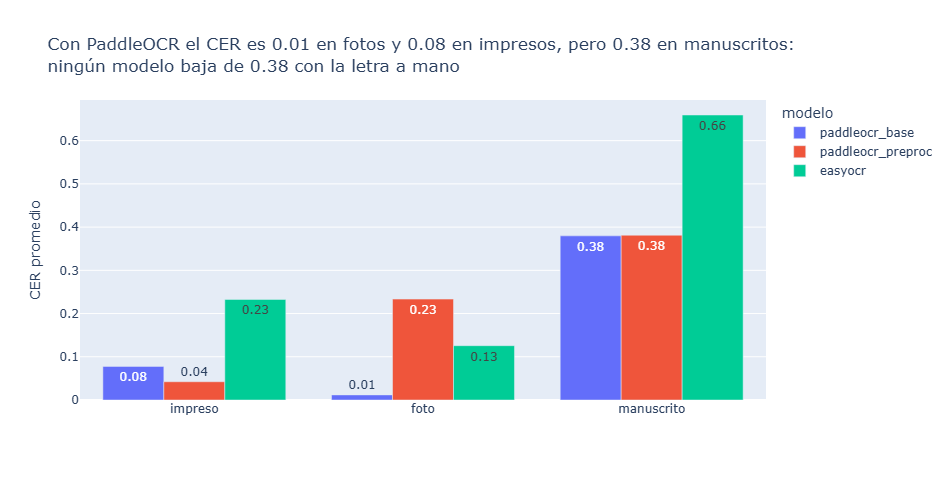

In [9]:
cer_tipo = eval_docs.groupby(["tipo", "modelo"], as_index=False)["cer"].mean()
base_tipo = cer_tipo[cer_tipo["modelo"] == "paddleocr_base"].set_index("tipo")["cer"]
mejor_manuscrito = cer_tipo[cer_tipo["tipo"] == "manuscrito"]["cer"].min()
fig = px.bar(cer_tipo, x="tipo", y="cer", color="modelo", barmode="group", text_auto=".2f",
             category_orders={"tipo": ["impreso", "foto", "manuscrito"], "modelo": list(ev.MODELOS_OCR)},
             title=f"Con PaddleOCR el CER es {base_tipo['foto']:.2f} en fotos y {base_tipo['impreso']:.2f} en impresos, pero "
                   f"{base_tipo['manuscrito']:.2f} en manuscritos:<br>ningún modelo baja de {mejor_manuscrito:.2f} con la letra a mano",
             labels={"cer": "CER promedio", "tipo": ""})
fig.show()

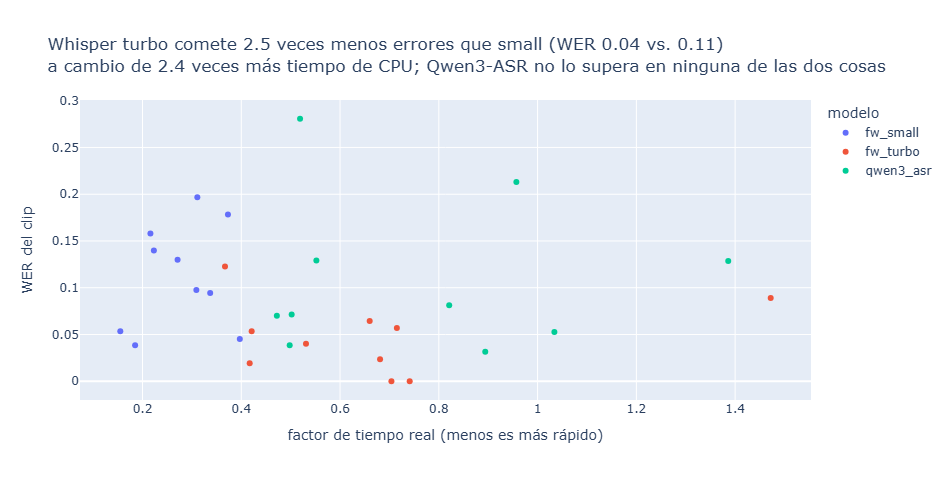

In [10]:
agr = tabla_asr.set_index("clave")
fig = px.scatter(eval_audio, x="factor_tiempo_real", y="wer", color="modelo", hover_data=["id"],
                 category_orders={"modelo": list(ev.MODELOS_ASR)},
                 title=f"Whisper turbo comete {agr.loc['fw_small', 'WER agregado'] / agr.loc['fw_turbo', 'WER agregado']:.1f} veces menos errores que small "
                       f"(WER {agr.loc['fw_turbo', 'WER agregado']:.2f} vs. {agr.loc['fw_small', 'WER agregado']:.2f})<br>a cambio de "
                       f"{agr.loc['fw_turbo', 'factor de tiempo real'] / agr.loc['fw_small', 'factor de tiempo real']:.1f} veces más tiempo de CPU; "
                       f"Qwen3-ASR no lo supera en ninguna de las dos cosas",
                 labels={"factor_tiempo_real": "factor de tiempo real (menos es más rápido)", "wer": "WER del clip"})
fig.show()

**Documentos: ninguna alternativa mejora a la línea base en el agregado.**

- **PaddleOCR + preprocesamiento** (CER 0,22) ayuda donde la base fallaba por la geometría: recupera la
  línea perdida de doc_001 (0,23 → 0,09) y mejora el diploma de 1921 (0,47 → 0,30). Pero en la foto del
  folleto doc_012 el clasificador de orientación **giró la página 180°**: leyó bien cada línea, pero de abajo
  hacia arriba, y el CER saltó de 0,02 a 0,66. En el promedio pesa más ese desastre que las mejoras.
- **EasyOCR** (CER 0,41) es tres veces más rápido en CPU (31 s por página), pero duplica el error. Entrega
  palabras sueltas en lugar de líneas, así que el orden de lectura se rompe en los textos a dos columnas o
  con interlineado irregular (doc_014: 0,32), y con los manuscritos produce símbolos sin sentido.

**Audio: el tamaño del modelo importa más que la familia.**

- **Whisper large-v3-turbo** baja el WER de 0,11 a **0,04** con el mismo motor y la misma configuración: 40
  errores en unas 900 palabras. Casi un 10 % de esos errores son solo convenciones de escritura («Dr.» por
  *doctor*). Lo paga con 2,4 veces más tiempo de CPU (factor de tiempo real 0,66), aún más rápido que el
  tiempo real.
- **Qwen3-ASR 0.6B** (WER 0,10), del tamaño de *small*, apenas mejora a la línea base y es el más lento en esta
  CPU (0,73), porque corre en float32 con PyTorch, sin la optimización int8 de CTranslate2. Tiene un error
  propio: la etiqueta «Música», que escribe como si fuera texto cuando oye la orquesta.

## 5. Casos difíciles

### 5.1 Manuscritos

In [11]:
for doc_id in [d for d in MUESTRA_DOCS if tipo[d] == "manuscrito"]:
    print(f"━━ {doc_id} · referencia: {referencias[doc_id][:160]!r}")
    for f in eval_docs[eval_docs["id"] == doc_id].itertuples():
        print(f"   {f.modelo:18s} CER {f.cer:.2f} · {f.texto[:160]!r}")
    print()

━━ doc_021 · referencia: 'Trujillo, 29 de julio 917\nSr. José María Eguren\nBarranco\nHondamente conmovido leí su atenta carta, \ncuyos términos le agradezco de veras. Ella me ha \nreanimado '
   paddleocr_base     CER 0.43 · 'Frigillo;, 9 de pilis 917\no. gori lavi Eque\nBannnco.\nhosvemente coumovid bé su aleut carth,\neugos timins le ageadgeo de visao. Elle me ks\nreanimad nenchio, n se'
   paddleocr_preproc  CER 0.42 · 'Fryillo,2 9 9g puis 9\nof. "ori lave Eon\nBannnco.\nThonvumente coumovid bé su aleut carth,\neugos tnminns le ogeadyeo de visas. Elle me hs\nreanimad nenchio, oan se'
   easyocr            CER 0.77 · 'fd5, 29 2 kEL 97?\nJ\nJLx:\n6\n>elcece\n7a Bzsesz 2nceez~8\n22 A ^1f-2118>\nZ+1\n4 28=\n628\n2\n27?\n24+0\n71\nc; ~\n~2\n4\n{eeci&\n~Ja\nFicu\nZ\nz\n4\n22;/\n42 &\n744\nZ\nA\nzt\n/e~\nlL 711'

━━ doc_022 · referencia: 'Agradezco muy sinceramente \nla fina atención de mi joven amigo \nLuis Antonio Eguiguren al \nobsequiarme los dos folletitos cuya \nlectura haré próxima

Los manuscritos son la frontera de los tres modelos, y cada uno falla a su manera:

- la base y el preprocesamiento producen texto deformado pero reconocible a ratos («Frigillo;, 9 de pilis
  917» por *Trujillo, 29 de julio 917*), con baja confianza, así que **avisan**;
- EasyOCR produce secuencias de símbolos («fd5, 29 2 kEL 97?») que ni siquiera se parecen al español.

El único manuscrito con error aceptable es la tarjeta de la Policía de 1921 (0,12), porque la mayor parte
del texto es el formulario impreso; lo llenado a mano («Capitán de navío…») sale casi siempre mal. El
diploma de Leguía muestra lo mismo: los tres modelos leen el texto caligrafiado impreso, pero ninguno el
nombre del condecorado escrito a pluma.

### 5.2 Audio con música y ambiente

Los noticieros mezclan narración con música orquestal y sonido ambiente. Como medida aproximada de
cuánta música o ruido hay en cada clip usamos la **fracción del clip sin voz** según el VAD.

In [12]:
sin_voz = 1 - transcripciones.set_index("id")["segundos_voz"] / transcripciones.set_index("id")["duracion_seg"]
eval_audio["fraccion_sin_voz"] = eval_audio["id"].map(sin_voz)
display(eval_audio.pivot_table(index=["id", "fraccion_sin_voz"], columns="modelo", values="wer").round(2).sort_index(level=1))
peor_clip = eval_audio[eval_audio["modelo"] == "fw_turbo"].sort_values("wer").iloc[-1]["id"]
alineacion = jiwer.process_words(limpiar(referencias[peor_clip]), limpiar(eval_audio.query("modelo == 'fw_turbo' and id == @peor_clip")["texto"].iloc[0]))
print(f"Clip con más errores para turbo: {peor_clip}")
print(jiwer.visualize_alignment(alineacion, show_measures=False)[:1500])

,modelo,fw_small,fw_turbo,qwen3_asr
id,fraccion_sin_voz,,,
clip_001,0.105386,0.18,0.09,0.13
clip_015,0.166102,0.09,0.02,0.03
clip_018,0.167797,0.10,0.06,0.08
clip_017,0.176252,0.05,0.00,0.05
clip_006,0.190278,0.14,0.06,0.13
clip_007,0.270769,0.20,0.00,0.21
clip_021,0.301075,0.04,0.02,0.04
clip_029,0.466495,0.13,0.04,0.07
clip_012,0.494670,0.05,0.05,0.07


Clip con más errores para turbo: clip_024
=== SENTENCE 1 ===

REF: este corto corresponde al acto de la inauguración del moderno edificio del teatro bahía cuya presencia pone una nota ** adelanto       al inicio del aristocrático balneario de ancón después de la bendición del local el presidente del directorio de la empresa peruana de cine pone a disposición del público aficionado al séptimo arte esta espaciosa y magnífica sala
HYP: **** ***** corresponde al acto de la inauguración del moderno edificio del teatro bahía cuya presencia pone una nota de adelanto edilicio     en  el aristocrático balneario de ancón después de la bendición  de local el presidente del directorio de la empresa peruana de cine pone a disposición del público aficionado al séptimo arte esta espaciosa y magnífica sala
        D     D                                                                                                            I                 S      S   S                                             

La música y el ambiente afectan **más a los modelos pequeños y a Qwen** que a turbo, pero no explican
todo:

- El clip con más música (clip_024, teatro de Ancón: 62 % del clip sin voz) es el peor para turbo (0,12) y
  para Qwen (0,28). Turbo omitió la primera frase («Este corto…»), que se dice sobre la música de entrada,
  y Qwen la convirtió en «Con dialecto».
- El clip del cardenal (clip_007) muestra el otro lado: con un 27 % sin voz, turbo lo transcribe perfecto
  (WER 0,00), mientras small y Qwen se equivocan en una de cada cinco palabras. La diferencia está en los
  nombres propios y en el ruido de la multitud en el aeropuerto, no en la música.
- La correlación entre la fracción del clip sin voz y el WER es débil (0,38 para turbo y 0,42 para Qwen, con
  solo 10 clips), así que la tomamos como indicio, no como prueba.

Una advertencia sobre la referencia: la escribió una sola persona. En algunos pasajes los tres modelos
coinciden entre sí y no con la referencia (por ejemplo, «una nota de adelanto edilicio» en clip_024), lo
que sugiere que parte del error medido puede ser de la propia referencia. No la corregimos después de ver
los resultados, para no sesgarla a favor de los modelos.

## 6. Extracción estructurada con un LLM local

**Modelo:** Qwen3-1.7B (Alibaba, Apache 2.0), en la laptop con `transformers`: ningún texto sale a una API.
Decodificación voraz (sin muestreo) y sin modo de razonamiento, así que el mismo texto da siempre el mismo JSON.

**Prompt estructurado** (en `extraccion_llm.py`): el modelo recibe el esquema, una lista cerrada de temas y
cuatro reglas: `null` si el dato no aparece, copiar fechas y nombres tal como están, no corregir errores
de OCR en las citas y no agregar claves. Los textos se recortan a 2500 caracteres para acotar el tiempo
en CPU.

In [13]:
print(ex.construir_prompt("(texto)", "documento")[0]["content"])

Eres un archivero que cataloga documentos y noticieros peruanos de 1910 a 1950.
Lee el texto y devuelve SOLO un objeto JSON válido con exactamente estas claves:
{
  "modalidad": "documento",
  "tema": uno de TEMAS,
  "resumen": "una o dos oraciones fieles al texto",
  "emisor": "quién firma o emite el documento, o null",
  "destinatario": "a quién va dirigido, o null",
  "fecha": "fecha tal como aparece en el texto, o null",
  "lugar": "lugar tal como aparece en el texto, o null",
  "monto": "cantidad de dinero tal como aparece, o null"
}

TEMAS = ["elecciones y partidos", "gobierno y Estado", "relaciones internacionales y guerra", "cultura, patrimonio y fiestas", "sociedad y vida cotidiana", "religión", "educación y ciencia", "economía y obras públicas", "correspondencia personal"]

Reglas:
- Usa null si el dato no aparece explícitamente en el texto. No inventes ni completes datos.
- Copia fechas, lugares, nombres y montos tal como están escritos.
- El texto viene de OCR o de reconoci

In [14]:
registros = pd.concat([
    documentos.assign(modalidad="documento", texto=documentos["texto_ocr"])[["id", "modalidad", "texto"]],
    transcripciones.assign(modalidad="audio", texto=transcripciones["texto_asr"])[["id", "modalidad", "texto"]],
], ignore_index=True)

tok = modelo_llm = None
salidas = []
for r in registros.itertuples():
    if not (ex.CACHE / f"{r.id}.json").exists() and modelo_llm is None:
        tok, modelo_llm = ex.cargar_modelo()
    salidas.append(ex.extraer(r.id, r.texto, r.modalidad, tok, modelo_llm))
salidas = pd.DataFrame(salidas)
print(f"Registros: {len(salidas)} · JSON válidos: {salidas['json_valido'].sum()} · "
      f"tiempo mediano {salidas['segundos'].median():.0f} s por registro · total {salidas['segundos'].sum() / 60:.0f} min")

Registros: 57 · JSON válidos: 57 · tiempo mediano 158 s por registro · total 148 min


In [15]:
fecha_extraccion = pd.Timestamp.now(tz="America/Lima").strftime("%Y-%m-%d")
# solo las claves del esquema (si el modelo inventó otras, se descartan y se cuentan); el JSON se publica seudonimizado
extraccion = ex.tabla_publicable(salidas.to_dict(orient="records"), reemplazos, fecha_extraccion)
extraccion.to_csv(DATOS / "extraccion_llm.csv", index=False)
print(f"datos/extraccion_llm.csv: {extraccion.shape} · claves inventadas descartadas: {extraccion['claves_extra_descartadas'].sum()}")
extraccion.head(4)

datos/extraccion_llm.csv: (57, 7) · claves inventadas descartadas: 0


,id,modalidad,campos_json,modelo_llm,fecha,json_valido,claves_extra_descartadas
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""elecciones y partidos"", ""resumen"": ""La Comisión. No. 17986 informa sob...",Qwen/Qwen3-1.7B · transformers en CPU (float32) · decodificación voraz · sin modo de razonamiento · máx. 3...,2026-10-25,True,0
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""gobierno y Estado"", ""resumen"": ""El Presidente de la República leerá su...",Qwen/Qwen3-1.7B · transformers en CPU (float32) · decodificación voraz · sin modo de razonamiento · máx. 3...,2026-10-25,True,0
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""economía y obras públicas"", ""resumen"": ""La Representación del Gobierno...",Qwen/Qwen3-1.7B · transformers en CPU (float32) · decodificación voraz · sin modo de razonamiento · máx. 3...,2026-10-25,True,0
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""gobierno y Estado"", ""resumen"": ""La ley N° 8901 busca subsanar anomalía...",Qwen/Qwen3-1.7B · transformers en CPU (float32) · decodificación voraz · sin modo de razonamiento · máx. 3...,2026-10-25,True,0


In [16]:
temas = pd.Series([json.loads(j).get("tema") for j in extraccion.loc[extraccion["json_valido"], "campos_json"]]).value_counts()
nulos = {k: np.mean([json.loads(j).get(k) is None for j in extraccion.loc[(extraccion["json_valido"]) & (extraccion["modalidad"] == "documento"), "campos_json"]])
         for k in ["emisor", "destinatario", "fecha", "lugar", "monto"]}
print("Temas asignados:", temas.to_dict())
print("Fracción de documentos con null:", {k: round(float(v), 2) for k, v in nulos.items()})

Temas asignados: {'gobierno y Estado': 36, 'cultura, patrimonio y fiestas': 9, 'elecciones y partidos': 5, 'relaciones internacionales y guerra': 2, 'sociedad y vida cotidiana': 2, 'economía y obras públicas': 1, 'religión': 1}
Fracción de documentos con null: {'emisor': 0.2, 'destinatario': 0.24, 'fecha': 0.32, 'lugar': 0.28, 'monto': 0.96}


### 6.1 Auditoría humana de 20 extracciones

**Muestra:** 10 documentos y 10 audios elegidos al azar (`random_state=2026`) con `scripts/kit_auditoria.py`,
que muestra el texto publicado al lado del JSON con un selector correcto/incorrecto por campo.

**Criterios de corrección** (fijados antes de auditar):

| Campo | Correcto si… |
|---|---|
| `tema` | es la categoría de la lista que mejor describe el contenido principal |
| `resumen` | todo lo que afirma está en el texto y recoge la idea principal |
| `emisor`, `destinatario`, `fecha`, `lugar`, `monto` | el valor está en el texto y cumple ese rol, o es `null` y el texto no trae el dato |
| `citas_clave` | cada cita está literalmente en la transcripción y es relevante |
| `numero_hablantes` | coincide con las marcas `[HABLANTE_n]` distintas |

Una extracción es **completamente correcta** solo si todos sus campos lo son.

In [17]:
muestra = muestra_auditoria(extraccion)
auditoria = json.loads((DATOS / "raw" / "auditoria" / "auditoria_llm.json").read_text(encoding="utf-8"))
filas = []
for r in muestra.itertuples():
    campos = json.loads(r.campos_json) if r.json_valido else {}
    juicios = {k: auditoria.get(f"{r.id}|{k}") for k in campos}
    filas.append({"id": r.id, "modalidad": r.modalidad, "campos": len(campos),
                  "campos_correctos": sum(v == "1" for v in juicios.values()),
                  "sin_revisar": sum(v is None for v in juicios.values()),
                  "completamente_correcta": bool(campos) and all(v == "1" for v in juicios.values()),
                  "campos_con_error": ", ".join(k for k, v in juicios.items() if v == "0"),
                  "nota": auditoria.get(f"{r.id}|nota", "")})
resultado_auditoria = pd.DataFrame(filas)
acuerdo = int(resultado_auditoria["completamente_correcta"].sum())
print(f"Extracciones completamente correctas: {acuerdo}/20 = {acuerdo / 20:.0%} · campos sin revisar: {resultado_auditoria['sin_revisar'].sum()}")
print(resultado_auditoria.groupby("modalidad")["completamente_correcta"].agg(["sum", "count"]).to_string())

Extracciones completamente correctas: 8/20 = 40% · campos sin revisar: 0
           sum  count
modalidad            
audio        5     10
documento    3     10


In [18]:
por_campo = {}
for r in muestra.itertuples():
    for k in (json.loads(r.campos_json) if r.json_valido else {}):
        por_campo.setdefault(k, []).append(auditoria.get(f"{r.id}|{k}") == "1")
print("Exactitud por campo:", {k: f"{np.mean(v):.0%} (n={len(v)})" for k, v in por_campo.items()})
errores = resultado_auditoria[~resultado_auditoria["completamente_correcta"]][["id", "modalidad", "campos_con_error", "nota"]]
errores

Exactitud por campo: {'modalidad': '100% (n=20)', 'tema': '85% (n=20)', 'resumen': '80% (n=20)', 'emisor': '70% (n=10)', 'destinatario': '50% (n=10)', 'fecha': '80% (n=20)', 'lugar': '75% (n=20)', 'monto': '100% (n=10)', 'citas_clave': '100% (n=10)', 'numero_hablantes': '80% (n=10)'}


,id,modalidad,campos_con_error,nota
0,doc_004,documento,"destinatario, fecha",Fecha: No es 1931\nLíneas reconocidas del texto están en desorden
1,doc_016,documento,lugar,Líneas reconocidas del texto están en desorden
2,doc_019,documento,resumen,Mal reconocimiento de texto
3,doc_017,documento,"resumen, emisor, destinatario, fecha, lugar",Mal reconocimiento de texto
4,doc_015,documento,"resumen, destinatario, fecha, lugar",Líneas reconocidas del texto están en desorden
5,doc_025,documento,"emisor, destinatario, fecha",Resumen: El nombre es Augusto B. Leguía
9,doc_018,documento,"tema, resumen, emisor, destinatario",Mal reconocimiento de texto\nLíneas reconocidas del texto están en desorden
10,clip_012,audio,"lugar, numero_hablantes","lugar: ""paranipo"" no existe como palabra en español\nnumero_hablantes: solo hay un narrador"
16,clip_011,audio,tema,"tema: ""migración"", no ""elecciones y partidos"""
17,clip_023,audio,tema,"tema: ""sociedad y vida cotidiana"", no ""gobierno y Estado"""


**Acuerdo LLM–humano: 8 de 20 extracciones completamente correctas (40 %).** Son 3 de 10 documentos y 5 de
10 audios. Campo por campo el resultado es mejor: 124 de 150 campos correctos (83 %). Pero basta un campo
equivocado para que la extracción entera no sirva sin revisión. El formato no fue el problema: los 57 JSON
del corpus son válidos y el modelo no inventó claves. El problema está en el contenido.

Los errores no se reparten al azar. Hay cuatro patrones:

1. **Si el OCR entrega basura, el LLM la redacta bien.** Los 4 manuscritos de la muestra fallan. Ante un
   texto deformado, el modelo no responde `null`: escribe un resumen coherente y llena los campos con
   fragmentos sin sentido. En doc_017 (carta de Bachmann a Palma) el destinatario es «al. el profimdo dolor
   que he» y el lugar, «wien». Es el error más peligroso, porque el JSON *parece* confiable. La regla «usa
   null si el dato no aparece» no lo evita: algo sí aparece.
2. **El orden de lectura del OCR se convierte en hechos falsos.** doc_015 es una página de *La Crónica* a
   varias columnas. El OCR intercala líneas de columnas vecinas, y el LLM une frases que no van juntas:
   - tomó «15 de la tarde» (una hora) como fecha;
   - ubicó en México una reunión con un ministro, cuando México es la sede de la Conferencia Interamericana
     que se menciona en otra columna.

   La auditoría anotó el mismo desorden de líneas en doc_004, doc_016 y doc_018.
3. **El rol equivocado.** `destinatario` y `lugar` son los campos con más errores (5 cada uno). El modelo
   pone cualquier cargo, institución o fecha que aparezca:
   - en la Ley 8901 (doc_004), como destinatario, al Congreso Constituyente, que es quien concedió las
     facultades legislativas; y como fecha, «1931», el año de un decreto-ley que la ley cita;
   - en el diploma de 1921 (doc_025), como destinatario, al Ministro de Relaciones Exteriores, que solo
     *refrenda*.
4. **En audio, errores de interpretación más que de lectura.** Las transcripciones de turbo son limpias, y
   los errores son de otro tipo:
   - `numero_hablantes`: en clip_012 y clip_015 el modelo contó a las personas que, según el narrador,
     «hacen uso de la palabra» o «dicen» algo (3 y 2), en vez de las marcas de hablante (solo hay
     `[HABLANTE_1]`). Aquí hay además una inconsistencia nuestra: el esquema del prompt describe las marcas
     como «[H1], [H2]…» y los textos las traen como `[HABLANTE_1]`. No lo corregimos después de auditar
     (regla de juego), pero es la primera mejora para una nueva versión;
   - `tema`: «gobierno y Estado» funciona como categoría por defecto. El modelo la asignó a 36 de los 57
     registros, incluida la semana scout de clip_023. La llegada de inmigrantes europeos (clip_011) quedó
     como «elecciones y partidos». La lista cerrada no tiene una categoría de migración; la más cercana
     habría sido «sociedad y vida cotidiana».

Sobre los criterios: un valor copiado con el error del reconocimiento se aceptó en doc_011 («ICTOR RAUL») y
se rechazó en doc_025 («Loguia» por Leguía) y en clip_012 («paranipo» por *paraninfo*). El 8/20 no depende de
esa diferencia, porque esos dos casos tienen además otros campos incorrectos.

**Conclusión:** Qwen3-1.7B sirve como **primer borrador de catalogación** para textos impresos de una
columna y narraciones de un solo locutor. Las 8 extracciones correctas son 1 impreso, 2 fotos y 5 audios. No
sirve para manuscritos ni para páginas a varias columnas. El error del LLM se suma al del OCR o el ASR: un
modelo de lenguaje no recupera lo que la etapa anterior leyó mal.

## 7. Comparativa y decisión

In [19]:
comparativa = pd.concat([
    tabla_ocr.assign(modalidad="documentos", metrica="CER").rename(columns={"CER agregado": "error agregado", "CER promedio por caso": "error promedio por caso"}),
    tabla_asr.assign(modalidad="audio", metrica="WER").rename(columns={"WER agregado": "error agregado", "WER promedio por caso": "error promedio por caso"}),
], ignore_index=True)[["modalidad", "modelo", "metrica", "error agregado", "error promedio por caso", "segundos por caso", "factor de tiempo real"]]
comparativa["rol"] = ["línea base" if c in ("paddleocr_base", "fw_small") else "alternativo" for c in pd.concat([tabla_ocr["clave"], tabla_asr["clave"]])]
comparativa.round(3)

,modalidad,modelo,metrica,error agregado,error promedio por caso,segundos por caso,factor de tiempo real,rol
0,documentos,PaddleOCR 3.7 · PP-OCRv6 (configuración base de la clase),CER,0.191,0.179,87.415,NaN,línea base
1,documentos,"PaddleOCR 3.7 · PP-OCRv6 + orientación, desdoblado UVDoc y orientación de líneas",CER,0.218,0.235,68.540,NaN,alternativo
2,documentos,EasyOCR 1.7 · CRAFT + reconocedor latino (es),CER,0.409,0.371,31.450,NaN,alternativo
3,audio,"faster-whisper small (int8, CPU, beam 5, VAD) · línea base",WER,0.111,0.113,16.010,0.276,línea base
4,audio,"faster-whisper large-v3-turbo (int8, CPU, beam 5, VAD)",WER,0.044,0.047,40.030,0.656,alternativo
5,audio,"Qwen3-ASR 0.6B (CPU, float32, tramos VAD de voz.py)",WER,0.097,0.110,38.195,0.734,alternativo


**Documentos: PaddleOCR base (PP-OCRv6) como modelo principal.** Tiene el menor error agregado (CER 0,19), da
una confianza por línea que funciona como alarma y es estable: no reordena páginas. Su costo es el más alto
en esta laptop (~1,5 min por página en CPU); con GPU sería de segundos. Para un archivo real usaría una
regla de dos pasos:

1. impresos y fotos van directo a la base;
2. las páginas con menos líneas de las esperadas o con mediana de confianza menor a 0,80 se repasan con el
   preprocesamiento o con revisión humana. Los manuscritos, en cambio, siempre necesitan transcripción
   humana o un modelo de visión-lenguaje con GPU, sabiendo que este puede inventar (sesión 10).

**Audio: faster-whisper large-v3-turbo con VAD y filtro de alucinaciones.** Es claramente el más preciso (WER
0,04) y sigue siendo más rápido que el tiempo real en una CPU de laptop de 2017. *Small* solo se justifica
si hay que procesar miles de horas sin GPU; Qwen3-ASR no aporta en este corpus.

**Extracción estructurada: Qwen3-1.7B local solo como borrador revisado.** Con 8/20 extracciones
completamente correctas, sus JSON no pueden publicarse sin una persona que los revise. Sí ahorran trabajo:
el 83 % de los campos ya viene bien y el formato es siempre válido. Antes de cambiar de modelo, lo
siguiente sería:

1. no extraer de textos con baja confianza de OCR (los manuscritos) y marcarlos para revisión manual;
2. corregir el prompt (las marcas `[HABLANTE_n]`, una categoría para migración y otra «sin tema claro»);
3. ordenar las líneas por columnas antes de pasar el texto al LLM.

In [20]:
OCR_ELEGIDO, ASR_ELEGIDO = "paddleocr_base", "fw_turbo"
cer_elegido = float(tabla_ocr.set_index("clave").loc[OCR_ELEGIDO, "CER agregado"])
wer_elegido = float(tabla_asr.set_index("clave").loc[ASR_ELEGIDO, "WER agregado"])

eval_docs.drop(columns=["descripcion_modelo"]).to_csv(DATOS / "evaluacion_documentos.csv", index=False)
eval_audio.drop(columns=["descripcion_modelo"]).to_csv(DATOS / "evaluacion_audio.csv", index=False)
metricas = {
    "ocr_elegido": ev.MODELOS_OCR[OCR_ELEGIDO], "asr_elegido": ev.MODELOS_ASR[ASR_ELEGIDO],
    "cer_base": float(cer_base), "wer_base": float(wer_base), "cer_elegido": cer_elegido, "wer_elegido": wer_elegido,
    "acuerdo_llm": acuerdo,
    "tabla_comparativa": comparativa.round(3).to_dict(orient="records"),
    "auditoria_errores": errores.to_dict(orient="records"),
}
(DATOS / "metricas.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Resultados Test: WER: {wer_elegido:.2f} | CER: {cer_elegido:.2f} | Acuerdo LLM-Humano: {acuerdo}/20")

Resultados Test: WER: 0.04 | CER: 0.19 | Acuerdo LLM-Humano: 8/20


### Reflexión por tipo de documento y de audio

| Tipo | Desempeño | Causa |
|---|---|---|
| **Foto** (folleto fotografiado, columnas curvas) | el mejor con la base: CER 0,01 | la imprenta de 1945 es nítida y de alto contraste; la curvatura y la sombra no impidieron detectar las líneas. El riesgo apareció al «corregir» la geometría: el preprocesamiento giró una foto al revés |
| **Impreso** (prensa y ley) | muy bueno, salvo omisiones: CER 0,08 | los errores no son de lectura sino de detección: una línea entera que no se ve |
| **Manuscrito** (cartas, tarjetas y diplomas de 1912-1921) | el peor: CER 0,38 con la base, 0,66 con EasyOCR | los modelos están entrenados con texto impreso y escenas; la cursiva de pluma, los trazos que se tocan y la ortografía de época están fuera de su distribución |
| **Narración limpia** (noticieros de Huascarán y Nacional Films) | WER de 0 a 0,06 con turbo | locutores profesionales, dicción clara y un solo hablante |
| **Narración sobre música** (inauguraciones, playas) | WER de 0,12 a 0,28 con turbo y Qwen | la frase inicial dicha sobre la música se pierde o se deforma; en los cierres musicales aparecen alucinaciones («¡Gracias!»), que en el corpus eliminó el filtro |
| **Discurso en vivo** (clip_027, Congreso, 1945) | transcripción legible; la diarización por tramos separa al orador del narrador | la acústica del recinto y los aplausos son el ruido más difícil del corpus, y ahí aparecieron las alucinaciones «¡Suscríbete!» y «Gracias» |

En una frase: **para la prensa peruana de 1939-1945 y los noticieros de los años cuarenta, el pipeline produce
texto buscable de buena calidad; la letra manuscrita sigue necesitando a una persona.**